In [35]:
import numpy as np              # Одномерные и многомерные массивы
import pandas as pd             # Таблицы (dataframe, series)
import matplotlib.pyplot as plt # Графика
import seaborn as sns           # Красивая графика для визуализации данных
import sklearn                  # Алгоритмы машинного обучения
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 40)

RANDOM_STATE = 42               # для воспроизводимости результатов
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

scikit-learn 1.6.1 | pandas 2.2.3


# Прогнозирование мошеннических вакансий

## 0. Описание задачи

Цель работы — по информации из объявления о работе определить, является ли вакансия мошеннической.

Это **задача бинарной классификации**. Целевая переменная `fraudulent` принимает значения:

- `0` — вакансия не мошенническая;
- `1` — вакансия помечена как мошенническая.

Ошибки двух типов имеют разную практическую цену: пропустить мошенническую вакансию (ложноотрицательное предсказание) может быть опаснее, чем отправить обычную вакансию на дополнительную проверку (ложноположительное предсказание).

Источник данных: [Real or Fake: Fake Job Posting Prediction на Kaggle](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction).

# 1. Чтение данных

Файл `fake_job_postings.csv` лежит в репозитории на GitHub. Ячейка ниже ищет данные по очереди: сначала рядом с ноутбуком, затем по ссылке на GitHub.

In [33]:
import os

FILE = 'fake_job_postings.csv'
DATA_URL = 'https://raw.githubusercontent.com/Gizmo43/Machine_Learning_2026/main/fake_job_postings.csv'

if os.path.exists(FILE):
    data_raw = pd.read_csv(FILE)
else:
    try:
        data_raw = pd.read_csv(DATA_URL)
    except Exception:
        from google.colab import files
        uploaded = files.upload()
        data_raw = pd.read_csv(next(iter(uploaded)))

data_raw.shape

(17880, 18)

Посмотрим на первые строки.

In [36]:
data_raw.head(3)

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a gr...","Food52, a fast-growing, James Beard ...",Experience with content management s...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Produ...,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video P...",Organised - Focused - Vibrant - Awes...,What we expect from you:Your key res...,What you will get from usThrough bei...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce So...,"Our client, located in Houston, is a...",Implement pre-commissioning and comm...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


In [8]:
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

Описание столбцов:

| Столбец | Тип | Смысл |
|---|---|---|
| `job_id` | идентификатор | номер объявления (для обучения не нужен) |
| `title` | текст | название вакансии |
| `company_profile` | текст | описание компании |
| `description` | текст | описание вакансии |
| `requirements` | текст | требования к кандидату |
| `benefits` | текст | предлагаемые условия |
| `location` | строка | «страна, регион, город» |
| `department`, `salary_range` | строка | отдел и вилка зарплаты (очень много пропусков) |
| `employment_type`, `required_experience`, `required_education`, `industry`, `function` | категории | тип занятости, опыт, образование, отрасль, функция |
| `telecommuting`, `has_company_logo`, `has_questions` | бинарные 0/1 | удалёнка, логотип компании, скрининговые вопросы |
| **`fraudulent`** | **целевая переменная 0/1** | **1 = фейковая вакансия** |

# 2. Разбиение на обучающую и тестовую выборки

Разбиваем данные **до** всех преобразований и статистик: так тестовая выборка остаётся «невидимой» и мы не допускаем утечки информации (пороги выбросов, масштаб, категории и т.д. считаем только по обучающей выборке).

Пропорция 3:1 (`test_size=0.25`). Так как классы несбалансированы, используем **стратифицированное** разбиение (`stratify=y`): доля фейков в обеих частях будет одинаковой.

Заодно из `location` берём страну (первая часть до запятой): полный `location` слишком детальный (тысячи уникальных значений), а страна — компактный и осмысленный признак. `job_id` — идентификатор, его исключаем.

In [9]:
from sklearn.model_selection import train_test_split

data = data_raw.copy()
data['country'] = data['location'].str.split(',').str[0].str.strip()

X = data.drop(columns=['fraudulent', 'job_id'])
y = data['fraudulent']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print('Размер обучающей выборки:', X_train.shape[0])
print('Размер тестовой выборки: ', X_test.shape[0])
print(f'Доля фейков в train: {y_train.mean():.4f}, в test: {y_test.mean():.4f}')

Размер обучающей выборки: 13410
Размер тестовой выборки:  4470
Доля фейков в train: 0.0485, в test: 0.0483


# 3. Визуализация данных и основные характеристики

Все графики и статистики строим **только по обучающей выборке**.

## 3.1. Баланс классов

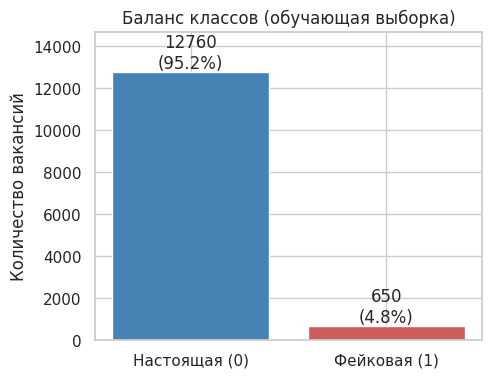

Соотношение классов: 19.6 : 1


In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = y_train.value_counts().sort_index()
ax.bar(['Настоящая (0)', 'Фейковая (1)'], counts.values, color=['steelblue', 'indianred'])
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v}\n({v / len(y_train):.1%})', ha='center', va='bottom')
ax.set_ylabel('Количество вакансий')
ax.set_title('Баланс классов (обучающая выборка)')
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

print(f'Соотношение классов: {counts[0] / counts[1]:.1f} : 1')

**Вывод.** Классы сильно несбалансированы: фейковых вакансий около 4,8 % (650 из 13 410), то есть примерно 1 к 20. Это определяет весь дальнейший ход работы.

## 3.2. Числовые характеристики из текста


In [34]:
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']
len_cols = [c + '_len' for c in text_cols]
words_cols = [c + '_words' for c in text_cols]
num_cols = len_cols + words_cols
bin_orig = ['telecommuting', 'has_company_logo', 'has_questions']


def add_text_features(d):
    """Добавляет длину (символы) и число слов для каждого текстового поля."""
    d = d.copy()
    for c in text_cols:
        d[c + '_len'] = d[c].str.len()
        d[c + '_words'] = d[c].str.split().str.len()
    return d


train = add_text_features(X_train)
test = add_text_features(X_test)

# копия для визуализации: признаки + целевая переменная
eda = train.assign(fraudulent=y_train)

eda[num_cols + bin_orig].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
title_len,13410.0,28.57,13.90,3.0,19.0,26.0,35.0,142.0
company_profile_len,10902.0,759.55,533.48,9.0,391.0,684.0,1018.0,5574.0
description_len,13409.0,1212.96,892.98,6.0,604.0,1010.0,1585.0,14907.0
requirements_len,11406.0,692.90,608.36,1.0,300.0,560.0,900.0,10864.0
benefits_len,7961.0,347.33,368.67,1.0,91.0,236.0,482.0,4429.0
title_words,13410.0,3.76,2.08,1.0,2.0,3.0,5.0,17.0
company_profile_words,10902.0,113.27,80.82,1.0,56.0,97.0,147.0,885.0
description_words,13409.0,169.62,123.07,0.0,86.0,144.0,224.0,2115.0
requirements_words,11406.0,91.67,81.16,0.0,39.0,74.0,119.0,1645.0
benefits_words,7961.0,49.81,54.94,0.0,11.0,32.0,70.0,694.0


## 3.3. Доля фейков в зависимости от значений признаков

Красная пунктирная линия — средняя доля фейков по всей обучающей выборке. Под столбцами указано число вакансий (`n`), чтобы не доверять группам из нескольких объектов. Пропуски в категориях обозначены как `Unknown`.

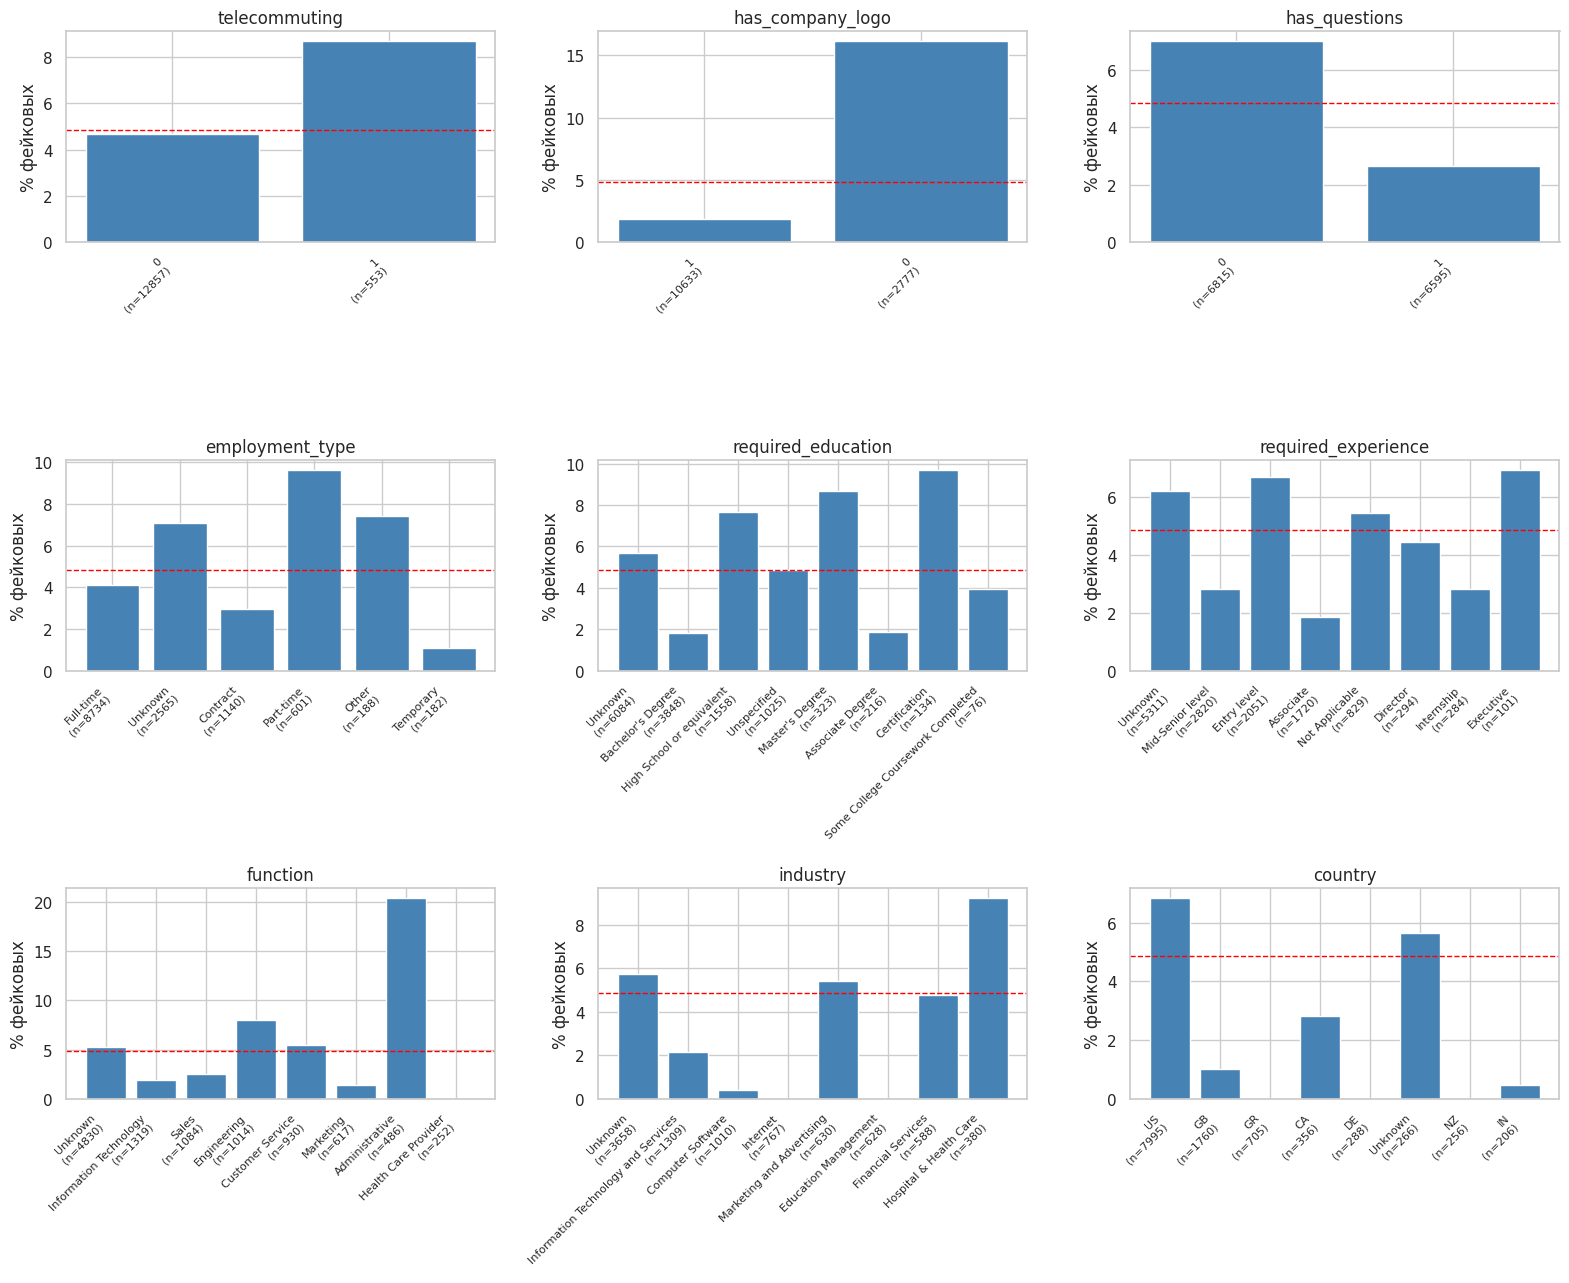

In [12]:
base_rate = y_train.mean() * 100


def plot_rate(ax, col, top=8, title=None):
    g = (eda.assign(_c=eda[col].fillna('Unknown'))
            .groupby('_c')['fraudulent'].agg(['mean', 'size']))
    g = g.sort_values('size', ascending=False).head(top)
    ax.bar(range(len(g)), g['mean'] * 100, color='steelblue')
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f'{i}\n(n={n})' for i, n in zip(g.index, g['size'])],
                       rotation=45, ha='right', fontsize=8)
    ax.axhline(base_rate, color='red', ls='--', lw=1)
    ax.set_title(title or col)
    ax.set_ylabel('% фейковых')


fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, c in zip(axes.ravel(), bin_orig + ['employment_type', 'required_education',
                                           'required_experience', 'function',
                                           'industry', 'country']):
    plot_rate(ax, c)
plt.tight_layout()
plt.show()

Сильнее всего отличаются объявления без логотипа: среди них фейков около 16 %, а среди объявлений с логотипом около 2 %. Похожая картина с вопросами для кандидата (7 % фейков без них и 2,6 % с ними). Удалёнка тоже повышает долю фейков, до 8,7 % против 4,7 %. Среди категорий выделяются тип занятости `Part-time` (около 9,7 %) и функция `Administrative` (около 20 %). По странам в США фейков около 6,8 %, в Великобритании около 1 %, а в Греции, Германии и Новой Зеландии в обучающей выборке их нет совсем. Если поле не заполнено (`Unknown`), доля фейков обычно тоже выше средней. Для маленьких групп проценты ненадёжны, поэтому под столбцами указан размер группы `n`.

## 3.4. Пропуски

Посмотрим, в каких столбцах есть пропуски.

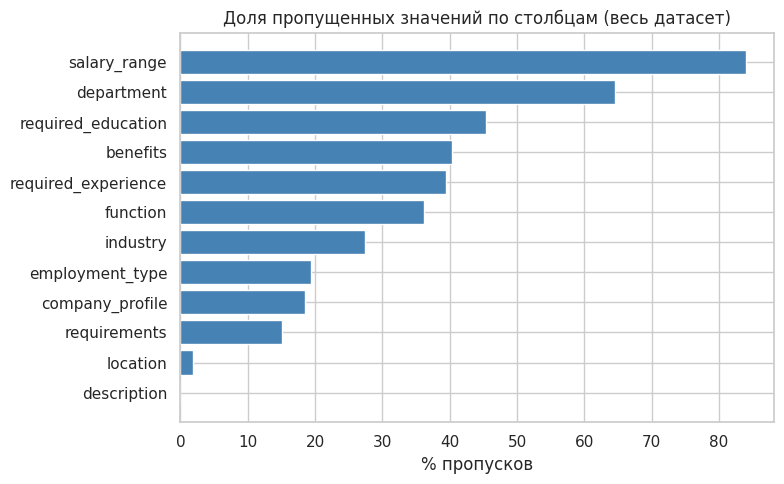

,% пропусков,% фейковых среди пропусков,% фейковых среди заполненных
признак,,,
salary_range,84.0,4.3,7.9
department,64.6,4.7,5.1
required_education,45.4,5.7,4.1
benefits,40.6,5.1,4.7
required_experience,39.6,6.2,4.0
function,36.0,5.3,4.6
industry,27.3,5.7,4.5
employment_type,19.1,7.1,4.3
company_profile,18.7,18.1,1.8


In [13]:
miss = data_raw.drop(columns=['job_id', 'fraudulent']).isna().mean().mul(100).sort_values()
miss = miss[miss > 0]

plt.figure(figsize=(8, 5))
plt.barh(miss.index, miss.values, color='steelblue')
plt.xlabel('% пропусков')
plt.title('Доля пропущенных значений по столбцам (весь датасет)')
plt.tight_layout()
plt.show()

rows = []
for c in X_train.columns:
    m = X_train[c].isna()
    if m.sum() >= 10:
        rows.append({'признак': c,
                     '% пропусков': m.mean() * 100,
                     '% фейковых среди пропусков': y_train[m].mean() * 100,
                     '% фейковых среди заполненных': y_train[~m].mean() * 100})
pd.DataFrame(rows).set_index('признак').sort_values('% пропусков', ascending=False).round(1)

Больше всего пропусков в `salary_range` (84 %), `department` (65 %) и `required_education` (45 %). Важно, что сам факт пропуска несёт информацию. Если у объявления нет описания компании, оно фейковое в 18 % случаев, а если есть, то только в 1,8 %, то есть в десять раз реже. Для типа занятости, образования, опыта и отрасли пропуск тоже слегка повышает долю фейков. Поэтому пропуски нельзя просто выбросить или заполнить средним, информацию о них надо сохранить.

## 3.5. Длина текстов в двух классах

Ось Y логарифмическая, так как длины сильно скошены вправо.

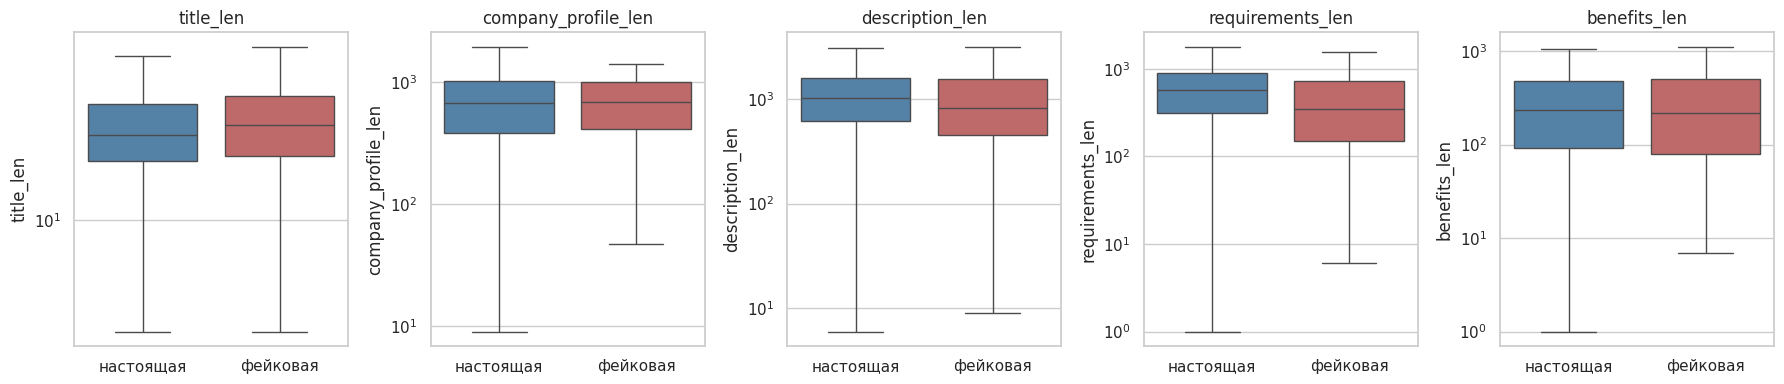

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, len_cols):
    sns.boxplot(data=eda[eda[c] > 0], x='fraudulent', y=c, ax=ax,
                palette=['steelblue', 'indianred'], showfliers=False)
    ax.set_yscale('log')
    ax.set_xticklabels(['настоящая', 'фейковая'])
    ax.set_xlabel('')
    ax.set_title(c)
plt.tight_layout()
plt.show()

Длины текстов в двух классах отличаются слабо. Заметно только, что требования у фейковых объявлений короче, и описание вакансии тоже немного короче. Длина названия, описания компании и условий почти одинакова. Значит, по одной длине текста фейк от настоящего объявления отличить трудно.

## 3.6. Корреляционная матрица

Строим по числовым и бинарным признакам вместе с целевой переменной. Отсутствующий текст считаем текстом нулевой длины.

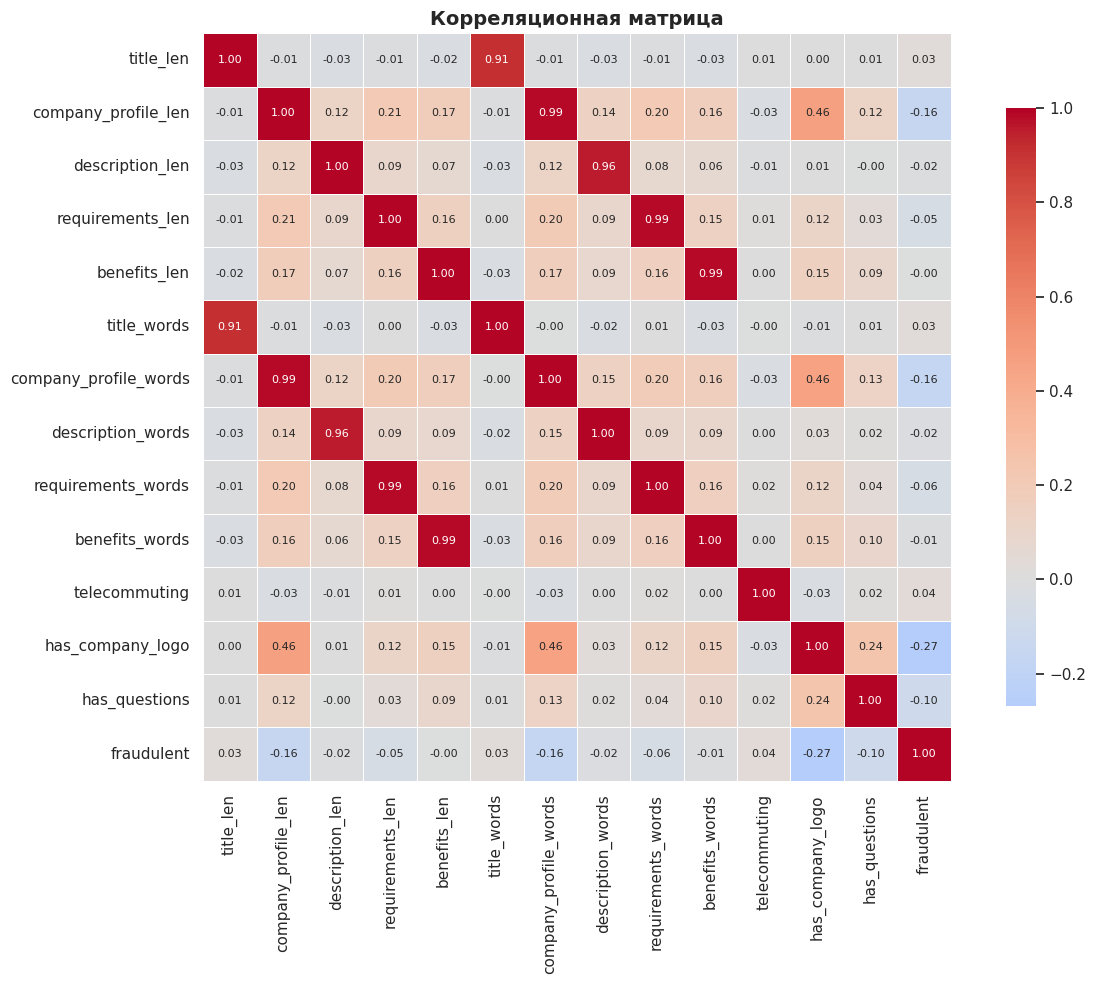

Корреляция с целевой переменной:
has_company_logo        -0.269
company_profile_words   -0.164
company_profile_len     -0.159
has_questions           -0.101
requirements_words      -0.055
requirements_len        -0.054
description_words       -0.020
description_len         -0.015
benefits_words          -0.007
benefits_len            -0.002
title_words              0.026
title_len                0.034
telecommuting            0.037
Name: fraudulent, dtype: float64


In [15]:
corr_cols = num_cols + bin_orig + ['fraudulent']
corr = eda[corr_cols].fillna(0).corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            linewidths=0.5, annot_kws={'size': 8}, cbar_kws={'shrink': 0.8})
plt.title('Корреляционная матрица', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Корреляция с целевой переменной:')
print(corr['fraudulent'].drop('fraudulent').sort_values().round(3))

Линейная связь признаков с целевой переменной слабая. Самая сильная у `has_company_logo` (−0,27): нет логотипа, значит, чаще фейк. Дальше идут длина описания компании (−0,16) и `has_questions` (−0,10), остальные почти нулевые. Поэтому от линейных методов многого ждать не стоит. Ещё видно, что длина текста в символах и число слов в нём почти полностью совпадают (корреляция от 0,91 до 0,99).

# 4. Выбросы

Бинарные признаки выбросов не имеют (только значения 0 и 1). Выбросы могут быть в длинах текстов. Посмотрим на них по правилу межквартильного размаха (IQR): выбросом считаем значение вне интервала $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$.

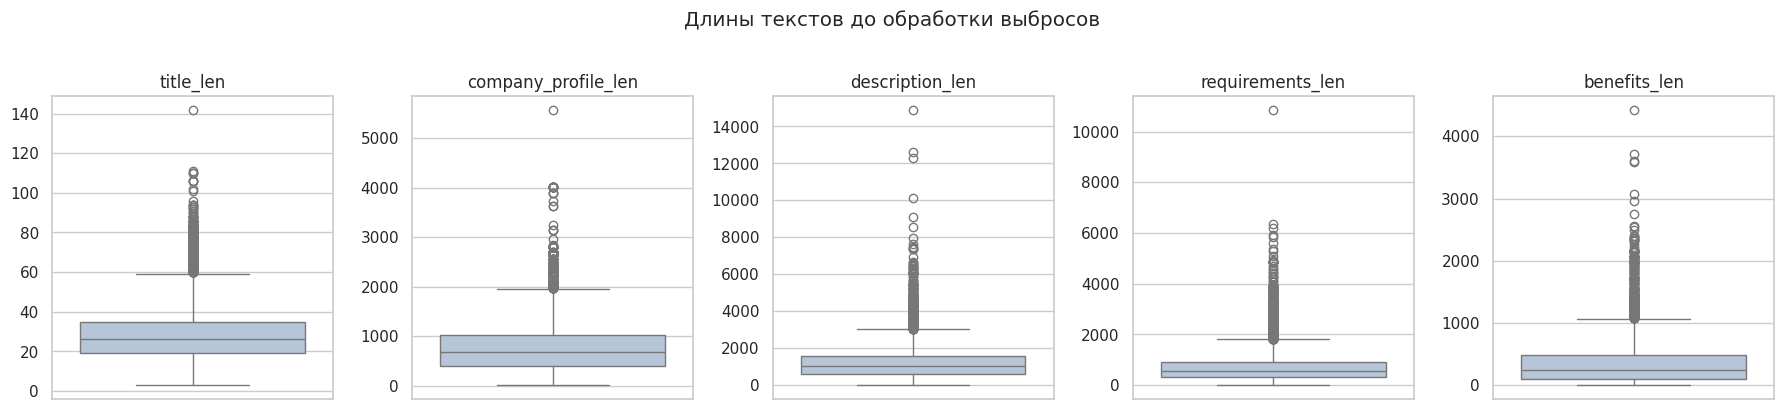

,% выбросов,% фейковых среди выбросов,% фейковых среди остальных
признак,,,
title_len,4.1,6.4,4.8
company_profile_len,3.7,0.0,1.9
description_len,4.0,6.2,4.8
requirements_len,4.7,3.4,4.8
benefits_len,4.6,8.0,4.5


In [16]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, len_cols):
    sns.boxplot(y=train[c].dropna(), ax=ax, color='lightsteelblue')
    ax.set_title(c)
    ax.set_ylabel('')
plt.suptitle('Длины текстов до обработки выбросов', y=1.02)
plt.tight_layout()
plt.show()

rows = []
for c in len_cols:
    s = train[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    is_out = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    rows.append({'признак': c,
                 '% выбросов': is_out.mean() * 100,
                 '% фейковых среди выбросов': y_train[s.index][is_out].mean() * 100,
                 '% фейковых среди остальных': y_train[s.index][~is_out].mean() * 100})
pd.DataFrame(rows).set_index('признак').round(1)

По правилу IQR выбросами оказывается около 4–5 % значений в каждой длине, то есть очень длинные тексты. Это не ошибки, а настоящие объявления, поэтому строки удалять не будем: так мы потеряли бы часть и без того редкого класса «фейк». К тому же среди выбросов доля фейков (от 0 до 8 %) не отличается заметно от доли среди остальных значений (2–5 %), то есть выбросы не образуют отдельную группу. Но слишком длинные тексты искажают стандартизацию и расстояния в методе ближайших соседей, поэтому ограничим их: значения выше 99-го и ниже 1-го процентиля заменим на сами эти процентили.

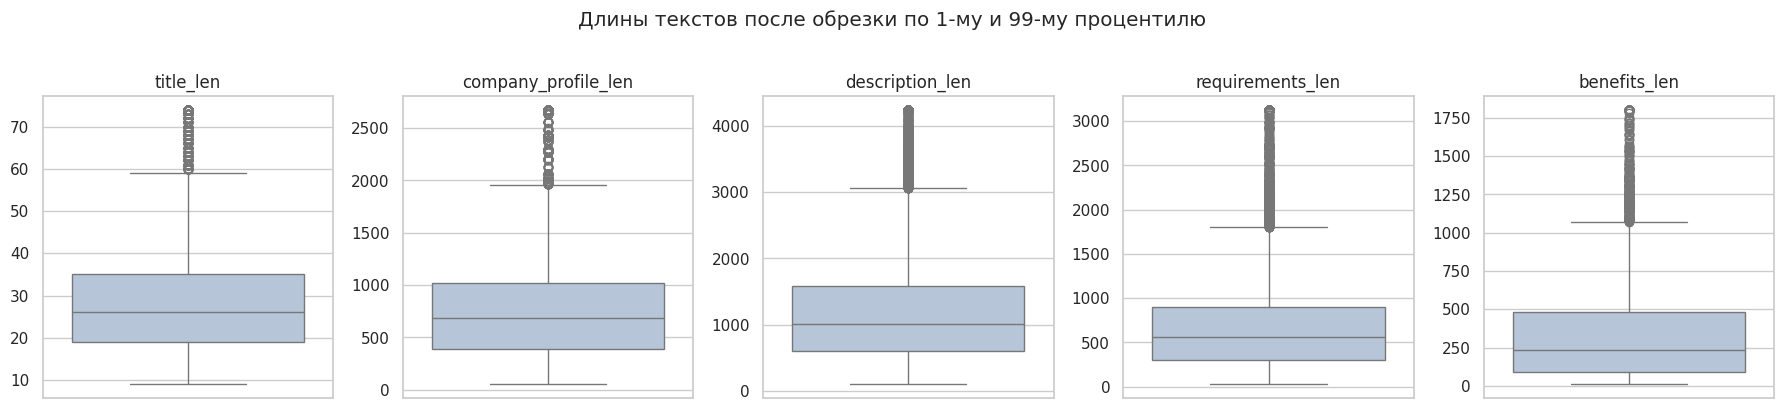

,граница снизу,граница сверху
title_len,9.0,74.0
company_profile_len,53.0,2676.0
description_len,102.0,4243.0
requirements_len,27.0,3131.0
benefits_len,11.0,1804.0


In [17]:
# Winsorization: значения ниже 1-го и выше 99-го процентиля обрезаем до этих границ.
# Границы считаем ТОЛЬКО по обучающей выборке и применяем к обеим.
low = train[num_cols].quantile(0.01)
high = train[num_cols].quantile(0.99)

train[num_cols] = train[num_cols].clip(lower=low, upper=high, axis=1)
test[num_cols] = test[num_cols].clip(lower=low, upper=high, axis=1)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, len_cols):
    sns.boxplot(y=train[c].dropna(), ax=ax, color='lightsteelblue')
    ax.set_title(c)
    ax.set_ylabel('')
plt.suptitle('Длины текстов после обрезки по 1-му и 99-му процентилю', y=1.02)
plt.tight_layout()
plt.show()

pd.DataFrame({'граница снизу': low[len_cols], 'граница сверху': high[len_cols]}).round(0)

После обрезки «хвосты» стали заметно короче (например, описание вакансии ограничено ≈4 200 символами вместо максимальных почти 15 000), а основная масса значений не изменилась. Границы посчитаны по обучающей выборке и без изменений применены к тестовой.

# 5. Обработка пропущенных значений


Пропусков много, но удалять строки нельзя: пропуски почти в каждом объявлении, а фейков и так мало. Поэтому для столбцов, где пропуск информативен (`company_profile`, `requirements`, `benefits`, `salary_range`, `department`), добавим бинарные признаки «значение отсутствует». У отсутствующего текста длину и число слов считаем равными нулю. Пропуски в категориальных признаках заполним отдельным значением `Unknown`: так мы не придумываем несуществующих данных. Столбцы `salary_range` и `department` целиком в модель не берём (у них слишком много пропусков и уникальных значений), оставляем только признаки их отсутствия. Вместо `location` используем страну.



In [18]:
flag_src = ['company_profile', 'requirements', 'benefits', 'salary_range', 'department']
flag_cols = [c + '_missing' for c in flag_src]
bin_cols = flag_cols + bin_orig
cat_cols = ['employment_type', 'required_experience', 'required_education',
            'function', 'industry', 'country']
feature_cols = num_cols + bin_cols + cat_cols

for d in (train, test):
    for c in flag_src:
        d[c + '_missing'] = d[c].isna().astype(int)
    d[num_cols] = d[num_cols].fillna(0)
    d[cat_cols] = d[cat_cols].fillna('Unknown')

print('Пропусков в признаках, идущих в модель: train =', int(train[feature_cols].isna().sum().sum()),
      ', test =', int(test[feature_cols].isna().sum().sum()))
print('Число признаков до кодирования:', len(feature_cols))

Пропусков в признаках, идущих в модель: train = 0 , test = 0
Число признаков до кодирования: 24


Теперь в признаках, которые пойдут в модель, пропусков нет ни в train, ни в test. Информация о том, что поле не было заполнено, сохранена в индикаторах `*_missing`, в нулевых длинах текстов и в категории `Unknown`.

# 6. Обработка категориальных признаков

Категориальных признаков шесть. Для метода ближайших соседей нужны числа, и способ кодирования здесь критичен: если закодировать категории номерами (`Full-time` = 0, `Contract` = 1, ...), то расстояние начнёт «думать», что категории упорядочены и что `Part-time` ближе к `Contract`, чем к `Full-time`. Это неверно, поэтому применяем one-hot кодирование: каждая категория превращается в столбец 0/1, и все категории оказываются на одинаковом расстоянии друг от друга.

У `industry` (131 значение) и `country` (90 значений) много редких категорий, которые только раздувают размерность. Параметр `min_frequency=50` объединяет категории, встретившиеся в обучающей выборке менее 50 раз, в одну группу «редкие» (`infrequent`). Кодировщик, как и всё остальное, обучаем только на обучающей выборке.

In [19]:
from sklearn.preprocessing import OneHotEncoder

print('Число уникальных значений в обучающей выборке:')
print(train[cat_cols].nunique())

encoder = OneHotEncoder(handle_unknown='infrequent_if_exist',
                        min_frequency=50, sparse_output=False)
encoder.fit(train[cat_cols])

print('\nПосле one-hot кодирования получилось столбцов:', len(encoder.get_feature_names_out(cat_cols)))
print(encoder.get_feature_names_out(cat_cols)[:12], '...')

Число уникальных значений в обучающей выборке:
employment_type          6
required_experience      8
required_education      14
function                38
industry               130
country                 89
dtype: int64

После one-hot кодирования получилось столбцов: 112
['employment_type_Contract' 'employment_type_Full-time'
 'employment_type_Other' 'employment_type_Part-time'
 'employment_type_Temporary' 'employment_type_Unknown'
 'required_experience_Associate' 'required_experience_Director'
 'required_experience_Entry level' 'required_experience_Executive'
 'required_experience_Internship' 'required_experience_Mid-Senior level'] ...


# 7. Нормализация

Метод ближайших соседей считает евклидово расстояние, поэтому признаки с большим масштабом «перетягивают» его на себя. Сейчас длины текстов измеряются сотнями и тысячами символов, а бинарные и one-hot признаки принимают значения 0/1: без нормализации расстояние определялось бы почти только длинами текстов, а логотип компании или тип занятости ничего бы не значили.

Поэтому числовые признаки (длины и числа слов) стандартизуем: $z = (x - \mu)/\sigma$, где $\mu$ и $\sigma$ считаем по обучающей выборке. Бинарные и one-hot признаки уже лежат в $[0, 1]$, их не трогаем.

(Для деревьев решений и случайного леса нормализация не нужна: они сравнивают значения признака с порогом, а не считают расстояния. Но нам она пригодится для KNN и логистической регрессии.)

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(train[num_cols])


def make_matrix(d):
    """Итоговая матрица признаков: стандартизованные числовые + бинарные + one-hot."""
    num = pd.DataFrame(scaler.transform(d[num_cols]), columns=num_cols, index=d.index)
    cat = pd.DataFrame(encoder.transform(d[cat_cols]),
                       columns=encoder.get_feature_names_out(cat_cols), index=d.index)
    return pd.concat([num, d[bin_cols].astype(float), cat], axis=1)


A_train = make_matrix(train)
A_test = make_matrix(test)

print('Размер матрицы признаков: train', A_train.shape, ', test', A_test.shape)
A_train[num_cols].describe().T[['mean', 'std', 'min', 'max']].round(3)

Размер матрицы признаков: train (13410, 130) , test (4470, 130)


,mean,std,min,max
title_len,-0.0,1.0,-1.446,3.377
company_profile_len,0.0,1.0,-1.114,3.734
description_len,-0.0,1.0,-1.451,3.675
requirements_len,0.0,1.0,-1.020,4.461
benefits_len,-0.0,1.0,-0.645,5.069
title_words,-0.0,1.0,-1.356,3.574
company_profile_words,0.0,1.0,-1.103,3.615
description_words,0.0,1.0,-1.460,3.651
requirements_words,0.0,1.0,-1.023,4.349
benefits_words,-0.0,1.0,-0.626,5.220


Среднее у каждого числового признака равно 0, а стандартное отклонение равно 1, значит, стандартизация выполнена правильно. Максимумы длин лежат примерно в пределах от 3,4 до 5,2 стандартных отклонений. Без обрезки выбросов у описания вакансии максимум был бы около 15, и один признак перетягивал бы на себя расстояние.

# 8. Классификатор ближайших соседей



Сначала заведём функцию для оценки модели и посчитаем два ориентира: тривиальный классификатор «всегда настоящая» и kNN с `k=5` (значение по умолчанию).

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

results = []   # сюда складываем результаты всех моделей


def evaluate(name, model, A_tr, y_tr, A_te, y_te, fit_data=None):
    """Обучает модель, считает метрики и сохраняет их в `results`.
    fit_data=(A_fit, y_fit) позволяет обучаться на другой выборке (например, после oversampling),
    а метрики считать по исходной обучающей."""
    A_fit, y_fit = fit_data if fit_data is not None else (A_tr, y_tr)
    model.fit(A_fit, y_fit)
    p_tr, p_te = model.predict(A_tr), model.predict(A_te)
    results.append({'Модель': name,
                    'Accuracy train': accuracy_score(y_tr, p_tr),
                    'Accuracy test': accuracy_score(y_te, p_te),
                    'Precision (фейк)': precision_score(y_te, p_te, zero_division=0),
                    'Recall (фейк)': recall_score(y_te, p_te),
                    'F1 (фейк)': f1_score(y_te, p_te)})
    return model, p_te


evaluate('Тривиальный: всегда «настоящая»', DummyClassifier(strategy='most_frequent'),
         A_train, y_train, A_test, y_test)
evaluate('KNN, k=5 (по умолчанию)', KNeighborsClassifier(n_neighbors=5),
         A_train, y_train, A_test, y_test)

pd.DataFrame(results).set_index('Модель').round(4)

,Accuracy train,Accuracy test,Precision (фейк),Recall (фейк),F1 (фейк)
Модель,,,,,
Тривиальный: всегда «настоящая»,0.9515,0.9517,0.0000,0.0000,0.0000
"KNN, k=5 (по умолчанию)",0.9799,0.9738,0.8075,0.6019,0.6897


Тривиальный классификатор («всегда настоящее») получает accuracy около 95 %, но не находит ни одного фейка, его recall равен нулю. Поэтому любая нормальная модель должна не просто обогнать 95 %, а находить фейки. Метод ближайших соседей с `k=5` даёт accuracy около 97,4 % и F1 около 0,69: он находит примерно 60 % фейков (recall), и 81 % его срабатываний верны (precision). По accuracy выигрыш у тривиального метода всего около двух процентных пунктов, а по F1 разница огромная, поэтому дальше смотрим в первую очередь на F1. Accuracy на обучающей выборке (98,0 %) немного выше, чем на тестовой (97,4 %), то есть есть небольшое переобучение.

# 9. Ошибки на обучающей и тестовой выборках. Выбор числа соседей

Ошибкой будем называть долю неверных ответов, то есть 1 − accuracy. Из-за дисбаланса ей одной доверять нельзя, поэтому добавим метрики для класса «фейк». Precision показывает, какая доля объявлений, названных фейковыми, действительно фейковые. Recall показывает, какую долю всех настоящих фейков мы нашли. F1 объединяет их в одно число.

Число соседей `k` нельзя выбирать по тестовой выборке, она нужна для итоговой честной оценки. Поэтому выбираем `k` кросс-валидацией на обучающей выборке по F1 для класса «фейк». Кривые ошибок на train и test нарисованы только для наглядности, как на лекции.


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

ks = [1, 3, 5, 7, 9, 11, 15, 21, 31]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def knn_curve(A_tr, A_te):
    """Для каждого k: ошибки train/test, F1 по кросс-валидации на train и F1 на test."""
    rows = []
    for k in ks:
        knn = KNeighborsClassifier(n_neighbors=k)
        cv_pred = cross_val_predict(knn, A_tr, y_train, cv=skf)
        knn.fit(A_tr, y_train)
        p_te = knn.predict(A_te)
        rows.append({'k': k,
                     'ошибка train': 1 - accuracy_score(y_train, knn.predict(A_tr)),
                     'ошибка test': 1 - accuracy_score(y_test, p_te),
                     'F1 (кросс-вал. на train)': f1_score(y_train, cv_pred),
                     'F1 test': f1_score(y_test, p_te)})
    return pd.DataFrame(rows).set_index('k')


curve = knn_curve(A_train, A_test)
best_k = int(curve['F1 (кросс-вал. на train)'].idxmax())
print('Оптимальное k по кросс-валидации:', best_k)
curve.round(4)

Оптимальное k по кросс-валидации: 1


,ошибка train,ошибка test,F1 (кросс-вал. на train),F1 test
k,,,,
1,0.0000,0.0266,0.7062,0.7302
3,0.0148,0.0255,0.6815,0.7047
5,0.0201,0.0262,0.6638,0.6897
7,0.0229,0.0289,0.6526,0.6407
9,0.0250,0.0289,0.6358,0.6346
11,0.0262,0.0311,0.6070,0.5971
15,0.0286,0.0320,0.5756,0.5680
21,0.0313,0.0342,0.5031,0.5174
31,0.0344,0.0398,0.4255,0.3946


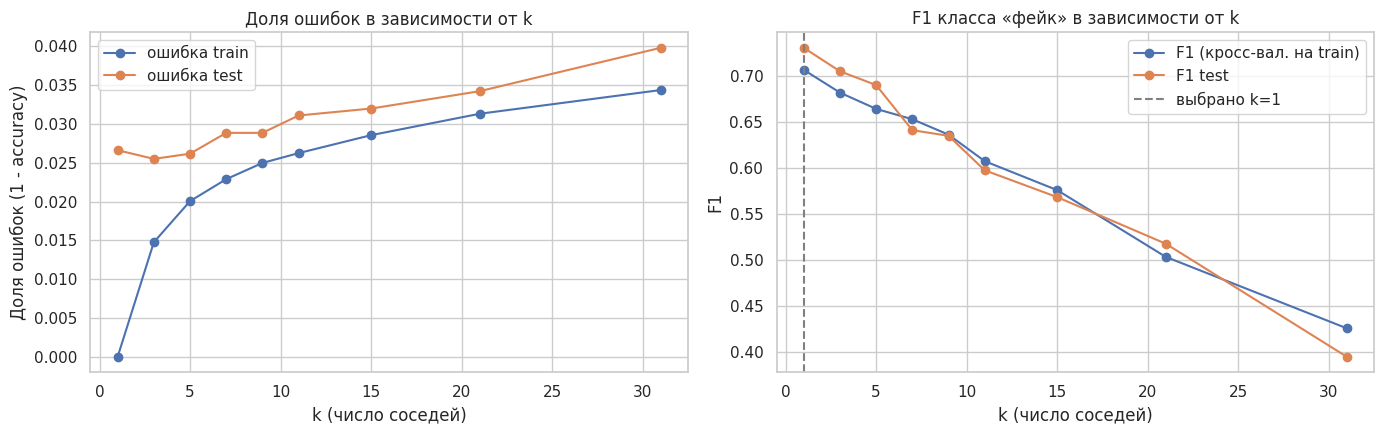

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

curve[['ошибка train', 'ошибка test']].plot(ax=axes[0], marker='o')
axes[0].set_title('Доля ошибок в зависимости от k')
axes[0].set_ylabel('Доля ошибок (1 - accuracy)')

curve[['F1 (кросс-вал. на train)', 'F1 test']].plot(ax=axes[1], marker='o')
axes[1].axvline(best_k, color='gray', ls='--', label=f'выбрано k={best_k}')
axes[1].set_title('F1 класса «фейк» в зависимости от k')
axes[1].set_ylabel('F1')
axes[1].legend()

for ax in axes:
    ax.set_xlabel('k (число соседей)')
plt.tight_layout()
plt.show()

На левом графике ошибка на обучающей выборке при `k=1` равна нулю: каждый объект является сам себе ближайшим соседом. С ростом `k` она увеличивается. Ошибка на тесте при `k` от 1 до 5 почти не меняется (около 2,6 %), а дальше растёт. По чистой ошибке лучшим было бы `k=3` (2,55 % против 2,66 %), но разница составляет всего 5 объектов из 4 470, а по F1 `k=1` заметно лучше. На правом графике F1 по кросс-валидации падает с ростом `k`, и лучшее значение даёт `k=1` (около 0,71 по кросс-валидации и 0,73 на тесте). Кривые идут рядом, значит, выбор по кросс-валидации подходит и для теста. Причина в том, что фейков мало: когда голосуют несколько соседей, редкий класс «перебивается» большинством, и модель реже предсказывает «фейк».


Обучаем kNN с выбранным `k` и печатаем матрицы рассогласования (строки: истинный класс, столбцы: предсказанный).

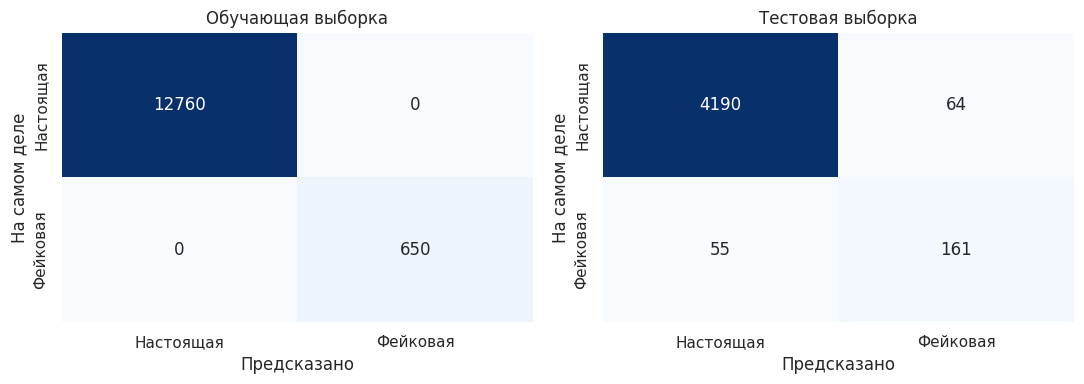

Тестовая выборка:
              precision    recall  f1-score   support

   Настоящая      0.987     0.985     0.986      4254
    Фейковая      0.716     0.745     0.730       216

    accuracy                          0.973      4470
   macro avg      0.851     0.865     0.858      4470
weighted avg      0.974     0.973     0.974      4470

Ошибка train = 0.0000, ошибка test = 0.0266


In [24]:
knn_best, p_best = evaluate(f'KNN, k={best_k} (выбрано по CV)', KNeighborsClassifier(n_neighbors=best_k),
                            A_train, y_train, A_test, y_test)
p_best_train = knn_best.predict(A_train)

labels = ['Настоящая', 'Фейковая']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (yt, yp, title) in zip(axes, [(y_train, p_best_train, 'Обучающая выборка'),
                                      (y_test, p_best, 'Тестовая выборка')]):
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('На самом деле')
    ax.set_title(title)
plt.tight_layout()
plt.show()

print('Тестовая выборка:')
print(classification_report(y_test, p_best, target_names=labels, digits=3))
print(f'Ошибка train = {1 - accuracy_score(y_train, p_best_train):.4f}, '
      f'ошибка test = {1 - accuracy_score(y_test, p_best):.4f}')

На обучающей выборке ошибок нет совсем: при `k=1` объект находит самого себя, поэтому такая матрица ничего не говорит о качестве. На тестовой выборке из 216 фейковых объявлений найдено 161 (recall около 0,75), 55 пропущено. Кроме того, 64 настоящих объявления ошибочно названы фейковыми (precision около 0,72). Общая ошибка 2,7 % (119 объектов из 4 470). Ошибок двух видов примерно поровну. На практике пропущенный фейк обычно хуже, чем ложная тревога.

**Почему оптимально именно такое `k`?** Проверим гипотезу про повторные публикации: посмотрим, как часто описание вакансии из тестовой выборки дословно встречается в обучающей, и как kNN работает на таких «знакомых» и на совсем новых вакансиях.

In [25]:
train_desc = set(X_train['description'].fillna(''))
dup = (X_test['description'].fillna('').isin(train_desc)).values

print(f'Тестовых вакансий, чьё описание дословно есть в обучающей выборке: {dup.sum()} из {len(dup)} ({dup.mean():.1%})')
print(f'Доля фейков среди «повторных»: {y_test[dup].mean():.1%}, среди новых: {y_test[~dup].mean():.1%}\n')

for name, mask in [('Описание уже есть в train', dup), ('Новое описание', ~dup)]:
    yt, yp = y_test[mask], p_best[mask]
    print(f'{name:28s} n={mask.sum():5d} | фейков {int(yt.sum()):3d} | '
          f'precision={precision_score(yt, yp, zero_division=0):.3f} '
          f'recall={recall_score(yt, yp):.3f} F1={f1_score(yt, yp):.3f}')

Тестовых вакансий, чьё описание дословно есть в обучающей выборке: 935 из 4470 (20.9%)
Доля фейков среди «повторных»: 8.0%, среди новых: 4.0%

Описание уже есть в train    n=  935 | фейков  75 | precision=0.974 recall=0.987 F1=0.980
Новое описание               n= 3535 | фейков 141 | precision=0.584 recall=0.617 F1=0.600


У 20,9 % тестовых объявлений (935 из 4 470) такое же описание уже есть в обучающей выборке. Среди них фейков вдвое больше (8,0 % против 4,0 %): мошенники действительно публикуют объявления повторно. На таких объявлениях метод ближайших соседей работает почти идеально (F1 около 0,98), потому что ближайший сосед это копия, и ответ просто копируется. На новых описаниях F1 падает до 0,60. Значит, итоговый результат 0,73 немного завышен из-за повторов, а на объявлениях, которых модель раньше не видела, качество ближе к 0,6. Это же объясняет, почему лучше всего `k=1`: чтобы найти копию, одного соседа достаточно. При разбиении данных для настоящего применения такие копии стоило бы держать в одной выборке, но здесь мы оставили случайное разбиение.

# 10. Другие классификаторы (по желанию)

Сравним метод ближайших соседей с тремя вариантами. Первый, логистическая регрессия: простая линейная модель, ей нужна нормализация, а она у нас уже есть. Второй, случайный лес: ансамбль деревьев, которому нормализация не нужна. Третий, модели на тексте: склеим пять текстовых полей и превратим их в числа методом TF-IDF (он считает, насколько характерно слово для объявления), после чего применим логистическую регрессию и метод ближайших соседей с косинусной метрикой. Для текста она подходит лучше евклидова расстояния.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

evaluate('Логистическая регрессия', LogisticRegression(max_iter=2000),
         A_train, y_train, A_test, y_test)

rf, _ = evaluate('Случайный лес (300 деревьев)',
                 RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
                 A_train, y_train, A_test, y_test)

pd.DataFrame(results).set_index('Модель').round(4)

,Accuracy train,Accuracy test,Precision (фейк),Recall (фейк),F1 (фейк)
Модель,,,,,
Тривиальный: всегда «настоящая»,0.9515,0.9517,0.0000,0.0000,0.0000
"KNN, k=5 (по умолчанию)",0.9799,0.9738,0.8075,0.6019,0.6897
"KNN, k=1 (выбрано по CV)",1.0000,0.9734,0.7156,0.7454,0.7302
Логистическая регрессия,0.9633,0.9624,0.7609,0.3241,0.4545
Случайный лес (300 деревьев),1.0000,0.9803,0.9848,0.6019,0.7471


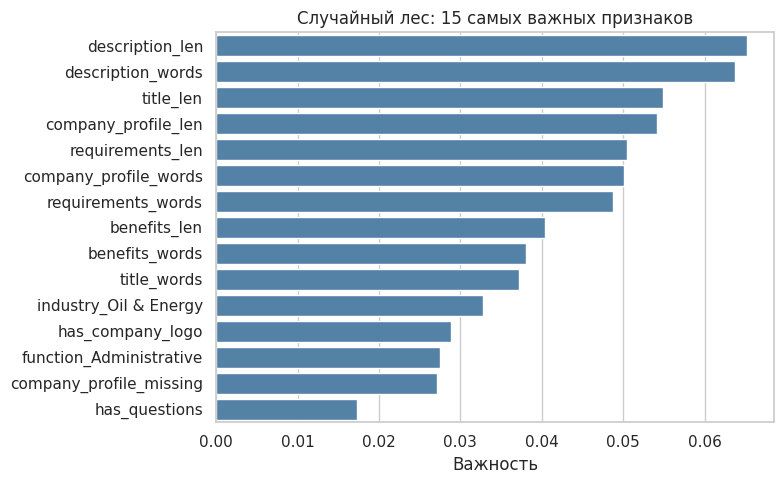

In [27]:
imp = pd.Series(rf.feature_importances_, index=A_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color='steelblue')
plt.title('Случайный лес: 15 самых важных признаков')
plt.xlabel('Важность')
plt.ylabel('')
plt.tight_layout()
plt.show()

Случайный лес лучше ближайших соседей: accuracy 98,0 %, F1 около 0,75. У него очень высокая precision (около 0,98), то есть почти всё, что он называет фейком, действительно фейк, но recall около 0,60, значит, около 40 % фейков он пропускает. Логистическая регрессия заметно слабее (F1 около 0,45, recall 0,32). Это согласуется с корреляционной матрицей: линейная связь признаков с целью слабая. Самые важные признаки леса это длины и число слов в текстах. Скорее всего, он, как и метод ближайших соседей, использует точные длины как «отпечаток» повторно опубликованных объявлений.

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer


def join_text(d):
    return (d['title'].fillna('') + ' ' + d['company_profile'].fillna('') + ' ' +
            d['description'].fillna('') + ' ' + d['requirements'].fillna('') + ' ' +
            d['benefits'].fillna(''))


tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3,
                        stop_words='english', sublinear_tf=True)
T_train = tfidf.fit_transform(join_text(X_train))
T_test = tfidf.transform(join_text(X_test))
print('Размер матрицы TF-IDF:', T_train.shape)

evaluate('TF-IDF + логрегрессия (balanced)',
         LogisticRegression(max_iter=3000, C=10, class_weight='balanced'),
         T_train, y_train, T_test, y_test)

for k in sorted({best_k, 5}):
    evaluate(f'TF-IDF + KNN (косинус), k={k}',
             KNeighborsClassifier(n_neighbors=k, metric='cosine', algorithm='brute'),
             T_train, y_train, T_test, y_test)

pd.DataFrame(results).set_index('Модель').round(4)

Размер матрицы TF-IDF: (13410, 20000)


,Accuracy train,Accuracy test,Precision (фейк),Recall (фейк),F1 (фейк)
Модель,,,,,
Тривиальный: всегда «настоящая»,0.9515,0.9517,0.0000,0.0000,0.0000
"KNN, k=5 (по умолчанию)",0.9799,0.9738,0.8075,0.6019,0.6897
"KNN, k=1 (выбрано по CV)",1.0000,0.9734,0.7156,0.7454,0.7302
Логистическая регрессия,0.9633,0.9624,0.7609,0.3241,0.4545
Случайный лес (300 деревьев),1.0000,0.9803,0.9848,0.6019,0.7471
TF-IDF + логрегрессия (balanced),0.9962,0.9866,0.8545,0.8704,0.8624
"TF-IDF + KNN (косинус), k=1",1.0000,0.9861,0.8348,0.8889,0.8610
"TF-IDF + KNN (косинус), k=5",0.9862,0.9841,0.8680,0.7917,0.8281


Когда мы перешли от длин текстов к самим словам, качество резко выросло. Логистическая регрессия на TF-IDF (с весами классов) даёт F1 около 0,86 (precision 0,85, recall 0,87). Метод ближайших соседей с косинусной метрикой при `k=1` даёт такой же результат (F1 около 0,86), при `k=5` F1 около 0,83. То есть на хороших признаках простой метод ближайших соседей не уступает логистической регрессии. Вывод: для текстов важнее хорошие признаки, чем выбор алгоритма. Значение для `k=5` приведено для сравнения, `k` здесь на тесте мы не подбирали.

# 11. Борьба с несбалансированностью классов (по желанию)

Классов 95 / 5, и модели склонны «не замечать» редкий класс. Что можно сделать:

* **веса классов** (`class_weight='balanced'`): ошибка на фейке штрафуется сильнее; поддерживается логистической регрессией и случайным лесом;
* **oversampling**: дублируем объекты редкого класса в обучающей выборке до равного числа с большим классом. kNN не умеет работать с весами классов, поэтому используем этот способ. Выборку дублируем **только в train** (иначе копии попадут и в тест, и оценка будет завышена);
* **взвешенное голосование соседей** (`weights='distance'`): ближние соседи весят больше.

In [29]:
evaluate('Логрегрессия, class_weight=balanced',
         LogisticRegression(max_iter=2000, class_weight='balanced'),
         A_train, y_train, A_test, y_test)

evaluate('Случайный лес, class_weight=balanced',
         RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1,
                                class_weight='balanced_subsample'),
         A_train, y_train, A_test, y_test)

# random oversampling редкого класса (только обучающая выборка)
rng = np.random.RandomState(RANDOM_STATE)
idx_major = np.where(y_train.values == 0)[0]
idx_minor = np.where(y_train.values == 1)[0]
idx_minor_up = rng.choice(idx_minor, size=len(idx_major), replace=True)
idx_all = np.concatenate([idx_major, idx_minor_up])
A_over, y_over = A_train.iloc[idx_all], y_train.iloc[idx_all]
print('После oversampling: классы 0/1 =', np.bincount(y_over))

for k in sorted({best_k, 3, 5, 11}):
    evaluate(f'KNN, k={k}, oversampling', KNeighborsClassifier(n_neighbors=k),
             A_train, y_train, A_test, y_test, fit_data=(A_over, y_over))

for k in [3, 5, 11]:
    evaluate(f'KNN, k={k}, weights=distance', KNeighborsClassifier(n_neighbors=k, weights='distance'),
             A_train, y_train, A_test, y_test)

pd.DataFrame(results).set_index('Модель').round(4)

После oversampling: классы 0/1 = [12760 12760]


,Accuracy train,Accuracy test,Precision (фейк),Recall (фейк),F1 (фейк)
Модель,,,,,
Тривиальный: всегда «настоящая»,0.9515,0.9517,0.0000,0.0000,0.0000
"KNN, k=5 (по умолчанию)",0.9799,0.9738,0.8075,0.6019,0.6897
"KNN, k=1 (выбрано по CV)",1.0000,0.9734,0.7156,0.7454,0.7302
Логистическая регрессия,0.9633,0.9624,0.7609,0.3241,0.4545
Случайный лес (300 деревьев),1.0000,0.9803,0.9848,0.6019,0.7471
TF-IDF + логрегрессия (balanced),0.9962,0.9866,0.8545,0.8704,0.8624
"TF-IDF + KNN (косинус), k=1",1.0000,0.9861,0.8348,0.8889,0.8610
"TF-IDF + KNN (косинус), k=5",0.9862,0.9841,0.8680,0.7917,0.8281
"Логрегрессия, class_weight=balanced",0.8632,0.8653,0.2480,0.8796,0.3870


У логистической регрессии с весами классов recall вырос с 0,32 до 0,88, то есть почти все фейки найдены. Но precision упала с 0,76 до 0,25: на каждый найденный фейк приходится около трёх ложных срабатываний. Accuracy снизилась с 96,2 % до 86,5 %, а F1 даже ухудшился (0,39 против 0,45). У случайного леса веса почти ничего не меняют (F1 0,746 против 0,747), потому что деревья растут до «чистых» листьев. У метода ближайших соседей oversampling при `k=1` не меняет результат, ведь дублирование не влияет на единственного соседа. При больших `k` recall растёт (0,80, 0,85 и 0,91 для `k=3, 5, 11`), но precision падает (0,58, 0,51 и 0,36), и F1 получается хуже, чем у `k=1`. Голосование с весами по расстоянию при `k=3` даёт F1 около 0,74 против 0,73, это улучшение в пределах случайных колебаний.

Итог такой: бороться с дисбалансом можно, но это обмен recall на precision, а общий F1 не растёт. Что выбрать, зависит от цены ошибок. Если пропустить фейк гораздо опаснее, чем ложно заблокировать честное объявление, подойдут oversampling и веса классов. Если важна точность срабатываний, лучше обычный метод ближайших соседей или случайный лес.


# 12. Исключение коррелированных переменных (по желанию)

Сильно коррелированные признаки несут почти одну и ту же информацию. Для kNN это вредно по простой причине: расстояние считается по всем признакам сразу, и «дублирующая» информация учитывается дважды, то есть фактически получает двойной вес. Для линейных моделей сильная корреляция вызывает мультиколлинеарность (неустойчивые коэффициенты), а деревьям она почти не мешает. Кроме того, меньше признаков значит быстрее счёт.

Найдём пары числовых признаков с |корреляцией| > 0.8 (по обучающей выборке).

In [30]:
c = train[num_cols].corr().abs()
pairs = [(a, b, c.loc[a, b]) for i, a in enumerate(num_cols) for b in num_cols[i + 1:] if c.loc[a, b] > 0.8]
pd.DataFrame(pairs, columns=['признак 1', 'признак 2', '|корреляция|']).round(3)

,признак 1,признак 2,|корреляция|
0,title_len,title_words,0.907
1,company_profile_len,company_profile_words,0.990
2,description_len,description_words,0.975
3,requirements_len,requirements_words,0.987
4,benefits_len,benefits_words,0.986


Все сильно коррелированные пары состоят из **длины в символах и числа слов одного и того же текстового поля** (|r| от 0,91 до 0,99): это почти одна и та же характеристика в разных единицах измерения. Признаки разных полей друг с другом так сильно не коррелируют.

In [31]:
# из каждой пары оставляем длину в символах, число слов убираем
A_train_r = A_train.drop(columns=words_cols)
A_test_r = A_test.drop(columns=words_cols)
print('Признаков было:', A_train.shape[1], ', стало:', A_train_r.shape[1])

curve_r = knn_curve(A_train_r, A_test_r)
best_k_r = int(curve_r['F1 (кросс-вал. на train)'].idxmax())
print('Оптимальное k по кросс-валидации без коррелированных признаков:', best_k_r)

name_full = f'KNN, k={best_k} (выбрано по CV)'
name_red = f'KNN, k={best_k_r}, без коррел. признаков'
evaluate(name_red, KNeighborsClassifier(n_neighbors=best_k_r),
         A_train_r, y_train, A_test_r, y_test)

pd.DataFrame(results).set_index('Модель').loc[[name_full, name_red]].round(4)

Признаков было: 130 , стало: 125
Оптимальное k по кросс-валидации без коррелированных признаков: 1


,Accuracy train,Accuracy test,Precision (фейк),Recall (фейк),F1 (фейк)
Модель,,,,,
"KNN, k=1 (выбрано по CV)",1.0,0.9734,0.7156,0.7454,0.7302
"KNN, k=1, без коррел. признаков",1.0,0.9736,0.7227,0.7361,0.7294


После удаления пяти лишних признаков (было 130, стало 125) качество практически не изменилось: F1 0,729 против 0,730, accuracy на тесте 97,36 % против 97,34 %, оптимальное `k` осталось прежним. То есть мы получили то же качество на более простой модели. Заметного выигрыша в точности нет, потому что в этой задаче длины и число слов играют второстепенную роль, но сам приём полезен: он убирает избыточность и ускоряет вычисления.

# 13. Сводная таблица и общие выводы

,Accuracy train,Accuracy test,Precision (фейк),Recall (фейк),F1 (фейк)
Модель,,,,,
TF-IDF + логрегрессия (balanced),0.9962,0.9866,0.8545,0.8704,0.8624
"TF-IDF + KNN (косинус), k=1",1.0000,0.9861,0.8348,0.8889,0.8610
"TF-IDF + KNN (косинус), k=5",0.9862,0.9841,0.8680,0.7917,0.8281
Случайный лес (300 деревьев),1.0000,0.9803,0.9848,0.6019,0.7471
"Случайный лес, class_weight=balanced",1.0000,0.9801,0.9704,0.6065,0.7464
"KNN, k=3, weights=distance",1.0000,0.9767,0.8111,0.6759,0.7374
"KNN, k=1, oversampling",1.0000,0.9734,0.7156,0.7454,0.7302
"KNN, k=1 (выбрано по CV)",1.0000,0.9734,0.7156,0.7454,0.7302
"KNN, k=1, без коррел. признаков",1.0000,0.9736,0.7227,0.7361,0.7294


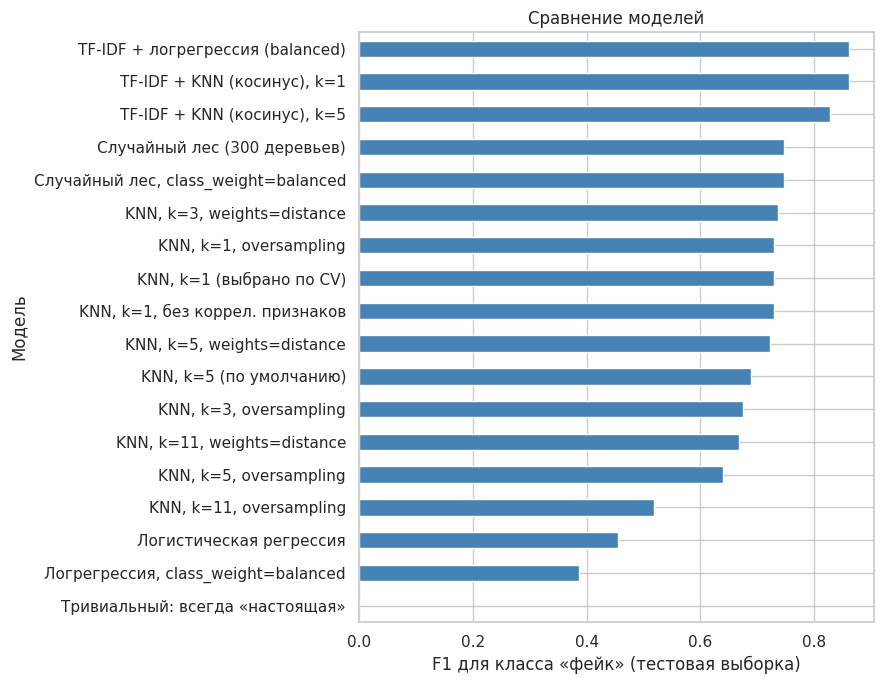

In [32]:
summary = pd.DataFrame(results).set_index('Модель').sort_values('F1 (фейк)', ascending=False)
display(summary.round(4))

plt.figure(figsize=(9, 7))
summary['F1 (фейк)'].sort_values().plot(kind='barh', color='steelblue')
plt.xlabel('F1 для класса «фейк» (тестовая выборка)')
plt.title('Сравнение моделей')
plt.tight_layout()
plt.show()

## Общие выводы

1. **Задача.** По 17 880 объявлениям (из них ≈5 % фейковых) решалась бинарная классификация «фейк / настоящая вакансия». Из-за дисбаланса 95/5 доля верных ответов (accuracy) почти ничего не говорит: тривиальный классификатор получает 95,2 % и не находит ни одного фейка. Поэтому качество оценивалось по precision, recall и F1 класса «фейк».

2. **Данные.** Самые заметные признаки фейковой вакансии: нет логотипа компании (16 % фейков против 2 %), нет описания компании (18 % против 1,8 %), нет скрининговых вопросов, указана удалёнка, определённые тип занятости и функция. Сам факт пропуска значения информативен, поэтому пропуски не удаляли, а превращали в индикаторы и категорию `Unknown`. Выбросы в длинах текстов (≈4–5 %) не удаляли, а ограничили по 1-му и 99-му процентилям. Категории кодировали one-hot (а не номерами, чтобы не вводить ложный порядок), числовые признаки стандартизовали, потому что kNN работает с расстояниями.

3. **kNN.** Число соседей выбрано кросс-валидацией на обучающей выборке: оптимально `k=1`. Результат на тесте: accuracy 97,3 %, precision 0,72, recall 0,75, F1 0,73 (из 216 фейков найдено 161, ложных срабатываний 64).

4. **Важная оговорка.** Около 21 % тестовых вакансий имеют в обучающей выборке копию с тем же описанием, и среди них фейков вдвое больше. На таких вакансиях kNN почти идеален (F1 ≈0,98), а на новых описаниях F1 ≈0,60. Поэтому реальное качество на «незнакомых» объявлениях ниже, чем показывает итоговая таблица. Это объясняет и выбор `k=1`.

5. **Другие методы.** Случайный лес на тех же признаках: F1 0,75 (precision 0,98, но recall 0,60). Логистическая регрессия: F1 0,45, так как линейная связь признаков с целью слабая. Самый заметный выигрыш дал переход к **самим текстам (TF-IDF)**: F1 ≈0,86 и у логистической регрессии, и у kNN с косинусной метрикой. То есть качество определяется прежде всего признаками, а не алгоритмом.

6. **Дисбаланс классов.** Веса классов и oversampling повышают recall (до 0,88–0,91), но платой становится резкое падение precision, а F1 не растёт. Выбор между «найти больше фейков» и «меньше ложных тревог» зависит от цены ошибок.

7. **Коррелированные признаки.** Длина в символах и число слов одного поля связаны с |r| = 0,91–0,99. Удаление пяти лишних признаков не ухудшило качество (F1 0,729 против 0,730), но упростило модель.
